In [1]:
import pandas as pd
from statsmodels.tsa.ar_model import AutoReg


In [2]:
df = pd.read_csv("data/BROWN-2006-2025.csv")

In [3]:
df["weather_code"] = (df["weather_code"] >= 51).astype(int)

In [4]:
df.head()

,date,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,cloud_cover_mean,relative_humidity_2m_mean,surface_pressure_mean,pressure_msl_mean,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,sunshine_duration,daylight_duration
0,2006-01-01,1,-0.748000,0.219130,-2.186684,89.208336,90.497190,1011.24950,1016.58740,2.9,0.0,2.030000,7.0,12.096214,24.840000,35.070538,5.27,0.457801,13678.8870,33160.043
1,2006-01-02,1,1.766583,4.668764,-1.135500,71.958336,87.895760,1017.85126,1023.17505,2.2,1.5,0.490000,5.0,10.823973,18.359999,188.230910,7.17,0.728814,25692.5590,33206.742
2,2006-01-03,1,1.443667,1.920640,0.614500,99.916664,93.093834,1011.23395,1016.52905,32.9,4.3,20.089998,21.0,25.305208,54.000000,47.441525,1.00,0.270114,0.0000,33257.145
3,2006-01-04,1,-0.587583,0.965135,-2.735500,89.833336,81.626680,1010.59350,1015.92500,0.1,0.1,0.000000,1.0,21.194187,45.360000,17.836770,5.33,0.633749,23905.1210,33311.200
4,2006-01-05,1,1.874917,4.276500,-0.687735,87.541664,93.460510,1000.87960,1006.11237,2.9,1.5,1.120000,13.0,13.183080,27.720000,207.552700,1.91,0.258215,1047.6377,33368.844


In [5]:
X1 = [
    "date",
    "weather_code",
    "cloud_cover_mean",
    "relative_humidity_2m_mean",
    "surface_pressure_mean",
    "pressure_msl_mean",
    "precipitation_sum",
    "rain_sum",
    "snowfall_sum",
    "precipitation_hours",
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "wind_direction_10m_dominant",
    "shortwave_radiation_sum",
    "et0_fao_evapotranspiration",
    "sunshine_duration",
    "daylight_duration",
]

y1 = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
]

X1_continuous = [
    "cloud_cover_mean",
    "relative_humidity_2m_mean",
    "surface_pressure_mean",
    "pressure_msl_mean",
    "precipitation_sum",
    "rain_sum",
    "snowfall_sum",
    "precipitation_hours",
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "wind_direction_10m_dominant",
    "shortwave_radiation_sum",
    "et0_fao_evapotranspiration",
    "sunshine_duration",
    "daylight_duration",
]

y1_continuous = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
]

X1_categorical = [
    "weather_code",
]

y1_categorical = []

X1_ordinal = []

y1_ordinal = []

X2 = [
    "date",
    "cloud_cover_mean",
    "relative_humidity_2m_mean",
    "surface_pressure_mean",
    "pressure_msl_mean",
    "precipitation_sum",
    "rain_sum",
    "snowfall_sum",
    "precipitation_hours",
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "wind_direction_10m_dominant",
    "shortwave_radiation_sum",
    "et0_fao_evapotranspiration",
    "sunshine_duration",
    "daylight_duration",
]

y2 = [
    "weather_code",
]

X2_continuous = [
    "cloud_cover_mean",
    "relative_humidity_2m_mean",
    "surface_pressure_mean",
    "pressure_msl_mean",
    "precipitation_sum",
    "rain_sum",
    "snowfall_sum",
    "precipitation_hours",
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "wind_direction_10m_dominant",
    "shortwave_radiation_sum",
    "et0_fao_evapotranspiration",
    "sunshine_duration",
    "daylight_duration",
]

y2_continuous = []

X2_categorical = []

y2_categorical = [
    "weather_code",
]

X2_ordinal = []

y2_ordinal = []

In [6]:
p = 7
lag_cols = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min"] + X1_categorical + X1_continuous

data = df.reset_index(drop=True)

y = data["temperature_2m_mean"]

lagged = {}
for col in lag_cols:
    for k in range(1, p + 1):
        lagged[f"{col}_lag{k}"] = data[col].shift(k)
X = pd.DataFrame(lagged)

X = X.iloc[p:].reset_index(drop=True)
y = y.iloc[p:].reset_index(drop=True)

In [7]:
y

0       -0.270917
1        3.860334
2        3.645751
3        5.512417
4        8.935334
          ...    
6929     4.462417
6930     8.993668
6931    11.145751
6932     6.891584
6933     7.952000
Name: temperature_2m_mean, Length: 6934, dtype: float64

In [8]:
X

,temperature_2m_mean_lag1,temperature_2m_mean_lag2,temperature_2m_mean_lag3,temperature_2m_mean_lag4,temperature_2m_mean_lag5,temperature_2m_mean_lag6,temperature_2m_mean_lag7,temperature_2m_max_lag1,temperature_2m_max_lag2,temperature_2m_max_lag3,...,sunshine_duration_lag5,sunshine_duration_lag6,sunshine_duration_lag7,daylight_duration_lag1,daylight_duration_lag2,daylight_duration_lag3,daylight_duration_lag4,daylight_duration_lag5,daylight_duration_lag6,daylight_duration_lag7
0,-2.162584,1.795750,1.874917,-0.587583,1.443667,1.766583,-0.748000,0.446805,3.469477,4.276500,...,0.0000,25692.5590,13678.8870,33494.910,33430.016,33368.844,33311.200,33257.145,33206.742,33160.043
1,-0.270917,-2.162584,1.795750,1.874917,-0.587583,1.443667,1.766583,3.805996,0.446805,3.469477,...,23905.1210,0.0000,25692.5590,33564.200,33494.910,33430.016,33368.844,33311.200,33257.145,33206.742
2,3.860334,-0.270917,-2.162584,1.795750,1.874917,-0.587583,1.443667,7.666197,3.805996,0.446805,...,1047.6377,23905.1210,0.0000,33637.773,33564.200,33494.910,33430.016,33368.844,33311.200,33257.145
3,3.645751,3.860334,-0.270917,-2.162584,1.795750,1.874917,-0.587583,7.564500,7.666197,3.805996,...,14390.3910,1047.6377,23905.1210,33715.477,33637.773,33564.200,33494.910,33430.016,33368.844,33311.200
4,5.512417,3.645751,3.860334,-0.270917,-2.162584,1.795750,1.874917,10.264501,7.564500,7.666197,...,31951.9360,14390.3910,1047.6377,33797.120,33715.477,33637.773,33564.200,33494.910,33430.016,33368.844
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6929,-2.408416,-1.881333,-3.168833,-0.985500,-8.820916,-9.318833,-3.160500,4.621462,3.431758,0.809301,...,31429.8930,31455.8400,23146.6520,32995.223,32970.234,32949.300,32932.473,32919.790,32911.297,32907.035
6930,4.462417,-2.408416,-1.881333,-3.168833,-0.985500,-8.820916,-9.318833,8.714500,4.621462,3.431758,...,18000.0000,31429.8930,31455.8400,33024.215,32995.223,32970.234,32949.300,32932.473,32919.790,32911.297
6931,8.993668,4.462417,-2.408416,-1.881333,-3.168833,-0.985500,-8.820916,11.648518,8.714500,4.621462,...,31383.7270,18000.0000,31429.8930,33057.164,33024.215,32995.223,32970.234,32949.300,32932.473,32919.790
6932,11.145751,8.993668,4.462417,-2.408416,-1.881333,-3.168833,-0.985500,13.731855,11.648518,8.714500,...,30130.2660,31383.7270,18000.0000,33094.016,33057.164,33024.215,32995.223,32970.234,32949.300,32932.473


In [9]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso, LinearRegression, ElasticNet
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split, TimeSeriesSplit
import numpy as np

In [10]:

# X_other, X_test, y_other, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)
# X_train, X_val, y_train, y_val = train_test_split(X_other, y_other, test_size=0.2/0.8, shuffle=False)
X_other, X_test, y_other, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

tss = TimeSeriesSplit(n_splits=5)

In [11]:
bins = [c for c in X.columns if c.startswith("weather_code")]
cons = [c for c in X.columns if c not in bins]
preprocessor = ColumnTransformer([
    ('con', StandardScaler(), cons),
    ('bin', 'passthrough', bins)
])

In [12]:
train_scores = []
val_scores = []

for train_idx, val_idx in tss.split(X_other):
    X_train = X_other.iloc[train_idx]
    y_train = y_other.iloc[train_idx]
    X_val = X_other.iloc[val_idx]
    y_val = y_other.iloc[val_idx]

    pipe_linearregression = Pipeline([
        ('prep', preprocessor),
        ('model', LinearRegression())
    ])
    pipe_linearregression.fit(X_train, y_train)

    train_scores.append(root_mean_squared_error(y_train, pipe_linearregression.predict(X_train)))
    val_scores.append(root_mean_squared_error(y_val, pipe_linearregression.predict(X_val)))

print("train RMSE LinearRegression mean:", round(np.mean(train_scores), 3))
print("val RMSE LinearRegression mean:", round(np.mean(val_scores), 3))
print("val RMSE LinearRegression std:", round(np.std(val_scores), 3))

pipe_linearregression.fit(X_other, y_other)
y_test_pred = pipe_linearregression.predict(X_test)
print("test RMSE LinearRegression:", round(root_mean_squared_error(y_test, y_test_pred), 3))

train RMSE LinearRegression mean: 2.421
val RMSE LinearRegression mean: 2.659
val RMSE LinearRegression std: 0.142
test RMSE LinearRegression: 2.487


best alpha Lasso: 0.00379269019073225
val RMSE Lasso mean: 2.649
val RMSE Lasso std: 0.136


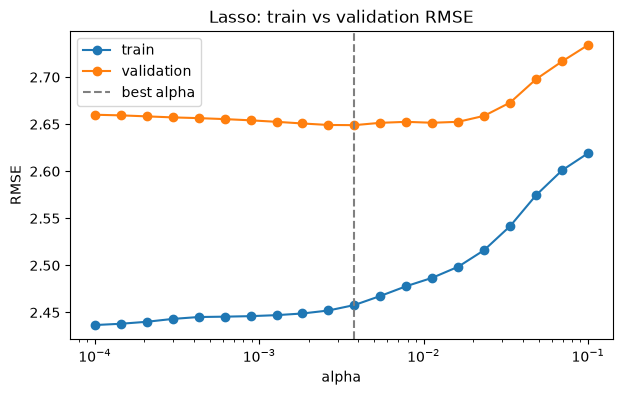

In [13]:
alphas = np.logspace(-4, -1, 20)
train_means = []
val_means = []
val_stds = []

for a in alphas:
    train_scores = []
    val_scores = []

    for train_idx, val_idx in tss.split(X_other):
        X_train = X_other.iloc[train_idx]
        y_train = y_other.iloc[train_idx]
        X_val = X_other.iloc[val_idx]
        y_val = y_other.iloc[val_idx]

        pipe_lasso = Pipeline([
            ('prep', preprocessor),
            ('model', Lasso(alpha = a, max_iter = 1000000))
        ])
        pipe_lasso.fit(X_train, y_train)

        train_scores.append(root_mean_squared_error(y_train, pipe_lasso.predict(X_train)))
        val_scores.append(root_mean_squared_error(y_val, pipe_lasso.predict(X_val)))

    train_means.append(np.mean(train_scores))
    val_means.append(np.mean(val_scores))
    val_stds.append(np.std(val_scores))

best_idx = np.argmin(val_means)
best_alpha_lasso = alphas[best_idx]

print("best alpha Lasso:", best_alpha_lasso)
print("val RMSE Lasso mean:", round(val_means[best_idx], 3))
print("val RMSE Lasso std:", round(val_stds[best_idx], 3))

plt.figure(figsize=(7, 4))
plt.semilogx(alphas, train_means, marker='o', label='train')
plt.semilogx(alphas, val_means, marker='o', label='validation')
plt.axvline(best_alpha_lasso, color='gray', linestyle='--', label='best alpha')
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.title('Lasso: train vs validation RMSE')
plt.legend()
plt.show()

In [14]:
pipe_lasso = Pipeline([
    ('prep', preprocessor),
    ('model', Lasso(alpha = best_alpha_lasso, max_iter = 1000000))
])
pipe_lasso.fit(X_other, y_other)
y_test_pred = pipe_lasso.predict(X_test)
print("test RMSE Lasso:", round(root_mean_squared_error(y_test, y_test_pred), 3))

test RMSE Lasso: 2.513


best alpha Ridge: 6.866488450042999e-05
val RMSE Ridge mean: 2.656
val RMSE Ridge std: 0.144


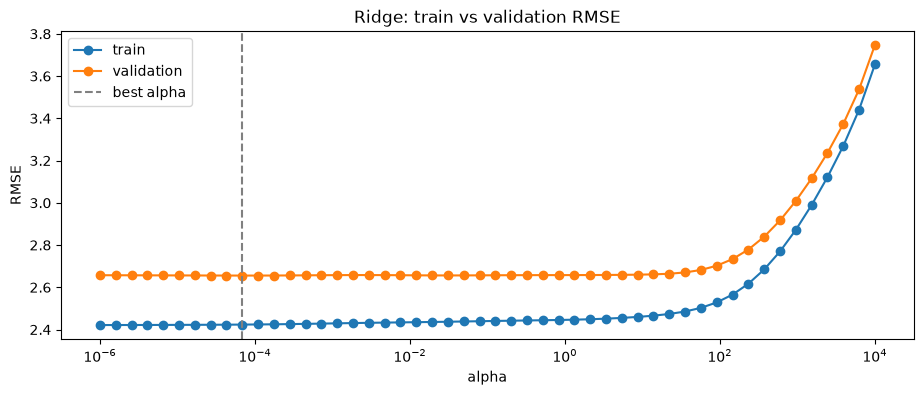

In [15]:
alphas = np.logspace(-6, 4, 50)
train_means = []
val_means = []
val_stds = []

for a in alphas:
    train_scores = []
    val_scores = []

    for train_idx, val_idx in tss.split(X_other):
        X_train = X_other.iloc[train_idx]
        y_train = y_other.iloc[train_idx]
        X_val = X_other.iloc[val_idx]
        y_val = y_other.iloc[val_idx]

        pipe_ridge = Pipeline([
            ('prep', preprocessor),
            ('model', Ridge(alpha = a))
        ])
        pipe_ridge.fit(X_train, y_train)

        train_scores.append(root_mean_squared_error(y_train, pipe_ridge.predict(X_train)))
        val_scores.append(root_mean_squared_error(y_val, pipe_ridge.predict(X_val)))

    train_means.append(np.mean(train_scores))
    val_means.append(np.mean(val_scores))
    val_stds.append(np.std(val_scores))

best_idx = np.argmin(val_means)
best_alpha_ridge = alphas[best_idx]

print("best alpha Ridge:", best_alpha_ridge)
print("val RMSE Ridge mean:", round(val_means[best_idx], 3))
print("val RMSE Ridge std:", round(val_stds[best_idx], 3))

plt.figure(figsize=(11, 4))
plt.semilogx(alphas, train_means, marker='o', label='train')
plt.semilogx(alphas, val_means, marker='o', label='validation')
plt.axvline(best_alpha_ridge, color='gray', linestyle='--', label='best alpha')
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.title('Ridge: train vs validation RMSE')
plt.legend()
plt.show()

In [16]:
pipe_ridge = Pipeline([
    ('prep', preprocessor),
    ('model', Ridge(alpha = best_alpha_ridge))
])
pipe_ridge.fit(X_other, y_other)
y_test_pred = pipe_ridge.predict(X_test)
print("test RMSE Ridge:", round(root_mean_squared_error(y_test, y_test_pred), 3))

test RMSE Ridge: 2.488


/opt/anaconda3/envs/data1030/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.464313e+03, tolerance: 7.873e+01
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/envs/data1030/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.269187e+03, tolerance: 1.630e+02
  model = cd_fast.enet_coordinate_descent(
/opt/anaconda3/envs/data1030/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasi

best alpha ElasticNet: 0.002154434690031882
best l1_ratio ElasticNet: 0.9
val RMSE ElasticNet mean: 2.652
val RMSE ElasticNet std: 0.137


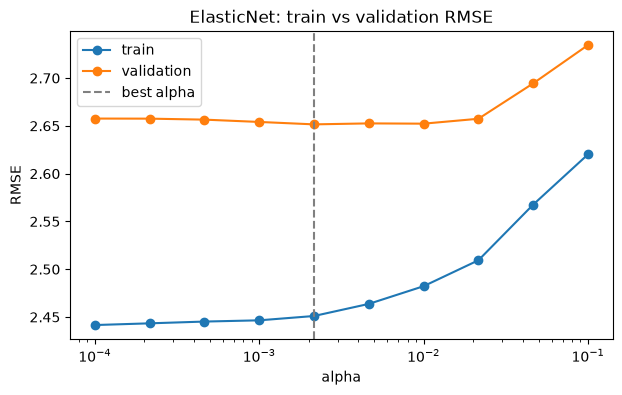

In [17]:
alphas = np.logspace(-4, -1, 10)
l1_ratios = np.linspace(0.1, 0.9, 5)
results = []

for l1 in l1_ratios:
    for a in alphas:
        train_scores = []
        val_scores = []

        for train_idx, val_idx in tss.split(X_other):
            X_train = X_other.iloc[train_idx]
            y_train = y_other.iloc[train_idx]
            X_val = X_other.iloc[val_idx]
            y_val = y_other.iloc[val_idx]

            pipe_en = Pipeline([
                ('prep', preprocessor),
                ('model', ElasticNet(alpha = a, l1_ratio = l1, max_iter = 10000, tol = 1e-3))
            ])
            pipe_en.fit(X_train, y_train)

            train_scores.append(root_mean_squared_error(y_train, pipe_en.predict(X_train)))
            val_scores.append(root_mean_squared_error(y_val, pipe_en.predict(X_val)))

        results.append({
            'l1_ratio': l1,
            'alpha': a,
            'train': np.mean(train_scores),
            'val': np.mean(val_scores),
            'val_std': np.std(val_scores)
        })

results_en = pd.DataFrame(results)
best_en = results_en.loc[results_en['val'].idxmin()]
best_alpha_en = best_en['alpha']
best_l1_en = best_en['l1_ratio']

print("best alpha ElasticNet:", best_alpha_en)
print("best l1_ratio ElasticNet:", best_l1_en)
print("val RMSE ElasticNet mean:", round(best_en['val'], 3))
print("val RMSE ElasticNet std:", round(best_en['val_std'], 3))

best_sub = results_en[results_en['l1_ratio'] == best_l1_en]

plt.figure(figsize=(7, 4))
plt.semilogx(best_sub['alpha'], best_sub['train'], marker='o', label='train')
plt.semilogx(best_sub['alpha'], best_sub['val'], marker='o', label='validation')
plt.axvline(best_alpha_en, color='gray', linestyle='--', label='best alpha')
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.title('ElasticNet: train vs validation RMSE')
plt.legend()
plt.show()

In [18]:
pipe_en = Pipeline([
    ('prep', preprocessor),
    ('model', ElasticNet(alpha = best_alpha_en, l1_ratio = best_l1_en, max_iter = 10000, tol = 1e-3))
])
pipe_en.fit(X_other, y_other)
y_test_pred = pipe_en.predict(X_test)
print("test RMSE ElasticNet:", round(root_mean_squared_error(y_test, y_test_pred), 3))

test RMSE ElasticNet: 2.511


In [19]:
train_scores = []
val_scores = []

for train_idx, val_idx in tss.split(X_other):
    X_train = X_other.iloc[train_idx]
    y_train = y_other.iloc[train_idx]
    X_val = X_other.iloc[val_idx]
    y_val = y_other.iloc[val_idx]

    pipe_poly = Pipeline([
        ('prep', preprocessor),
        ('poly', PolynomialFeatures(degree = 2)),
        ('model', LinearRegression())
    ])
    pipe_poly.fit(X_train, y_train)

    train_scores.append(root_mean_squared_error(y_train, pipe_poly.predict(X_train)))
    val_scores.append(root_mean_squared_error(y_val, pipe_poly.predict(X_val)))

print("train RMSE Poly mean:", round(np.mean(train_scores), 3))
print("val RMSE Poly mean:", round(np.mean(val_scores), 3))
print("val RMSE Poly std:", round(np.std(val_scores), 3))

pipe_poly.fit(X_other, y_other)
y_test_pred = pipe_poly.predict(X_test)
print("test RMSE Poly:", round(root_mean_squared_error(y_test, y_test_pred), 3))

train RMSE Poly mean: 0.0
val RMSE Poly mean: 6.449
val RMSE Poly std: 1.561
test RMSE Poly: 10.79


best alpha Poly Lasso: 0.1
val RMSE Poly Lasso mean: 2.617
val RMSE Poly Lasso std: 0.135


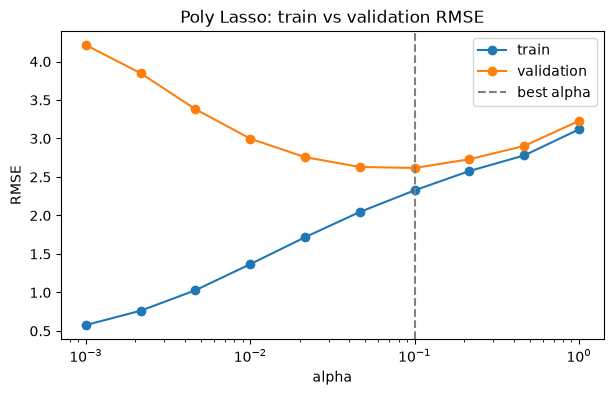

In [20]:
alphas = np.logspace(0, -3, 10)
train_mat = np.zeros((5, len(alphas)))
val_mat = np.zeros((5, len(alphas)))

for f, (train_idx, val_idx) in enumerate(tss.split(X_other)):
    X_train = X_other.iloc[train_idx]
    y_train = y_other.iloc[train_idx]
    X_val = X_other.iloc[val_idx]
    y_val = y_other.iloc[val_idx]

    prep_poly = Pipeline([
        ('prep', preprocessor),
        ('poly', PolynomialFeatures(degree = 2, include_bias = False)),
        ('scale', StandardScaler())
    ])
    Xt_train = prep_poly.fit_transform(X_train)
    Xt_val = prep_poly.transform(X_val)

    model = Lasso(max_iter = 10000, tol = 1e-3, warm_start = True)

    for j, a in enumerate(alphas):
        model.set_params(alpha = a)
        model.fit(Xt_train, y_train)

        train_mat[f, j] = root_mean_squared_error(y_train, model.predict(Xt_train))
        val_mat[f, j] = root_mean_squared_error(y_val, model.predict(Xt_val))

train_means = train_mat.mean(axis = 0)
val_means = val_mat.mean(axis = 0)
val_stds = val_mat.std(axis = 0)

best_idx = np.argmin(val_means)
best_alpha_poly_lasso = alphas[best_idx]

print("best alpha Poly Lasso:", best_alpha_poly_lasso)
print("val RMSE Poly Lasso mean:", round(val_means[best_idx], 3))
print("val RMSE Poly Lasso std:", round(val_stds[best_idx], 3))

plt.figure(figsize=(7, 4))
plt.semilogx(alphas, train_means, marker='o', label='train')
plt.semilogx(alphas, val_means, marker='o', label='validation')
plt.axvline(best_alpha_poly_lasso, color='gray', linestyle='--', label='best alpha')
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.title('Poly Lasso: train vs validation RMSE')
plt.legend()
plt.show()

In [21]:
pipe_poly_lasso = Pipeline([
    ('prep', preprocessor),
    ('poly', PolynomialFeatures(degree = 2, include_bias = False)),
    ('scale', StandardScaler()),
    ('model', Lasso(alpha = best_alpha_poly_lasso, max_iter = 10000, tol = 1e-3))
])
pipe_poly_lasso.fit(X_other, y_other)
y_test_pred = pipe_poly_lasso.predict(X_test)
print("test RMSE Poly Lasso:", round(root_mean_squared_error(y_test, y_test_pred), 3))

test RMSE Poly Lasso: 2.454


best alpha Poly Ridge: 1128.8378916846884
val RMSE Poly Ridge mean: 3.24
val RMSE Poly Ridge std: 0.455


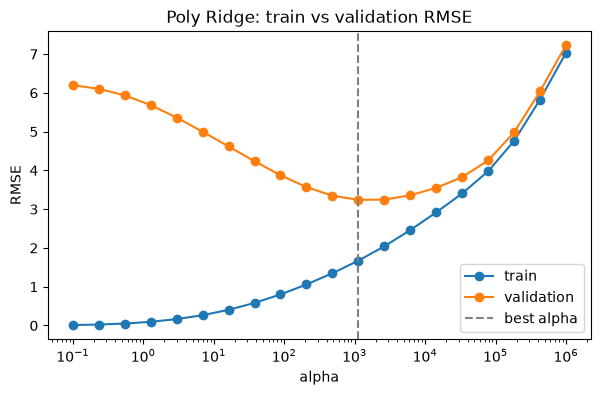

In [23]:
alphas = np.logspace(-1, 6, 20)
train_mat = np.zeros((5, len(alphas)))
val_mat = np.zeros((5, len(alphas)))

for f, (train_idx, val_idx) in enumerate(tss.split(X_other)):
    X_train = X_other.iloc[train_idx]
    y_train = y_other.iloc[train_idx]
    X_val = X_other.iloc[val_idx]
    y_val = y_other.iloc[val_idx]

    prep_poly = Pipeline([
        ('prep', preprocessor),
        ('poly', PolynomialFeatures(degree = 2, include_bias = False)),
        ('scale', StandardScaler())
    ])
    Xt_train = prep_poly.fit_transform(X_train)
    Xt_val = prep_poly.transform(X_val)

    for j, a in enumerate(alphas):
        model = Ridge(alpha = a)
        model.fit(Xt_train, y_train)

        train_mat[f, j] = root_mean_squared_error(y_train, model.predict(Xt_train))
        val_mat[f, j] = root_mean_squared_error(y_val, model.predict(Xt_val))

train_means = train_mat.mean(axis = 0)
val_means = val_mat.mean(axis = 0)
val_stds = val_mat.std(axis = 0)

best_idx = np.argmin(val_means)
best_alpha_poly_ridge = alphas[best_idx]

print("best alpha Poly Ridge:", best_alpha_poly_ridge)
print("val RMSE Poly Ridge mean:", round(val_means[best_idx], 3))
print("val RMSE Poly Ridge std:", round(val_stds[best_idx], 3))

plt.figure(figsize=(7, 4))
plt.semilogx(alphas, train_means, marker='o', label='train')
plt.semilogx(alphas, val_means, marker='o', label='validation')
plt.axvline(best_alpha_poly_ridge, color='gray', linestyle='--', label='best alpha')
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.title('Poly Ridge: train vs validation RMSE')
plt.legend()
plt.show()

In [24]:
pipe_poly_ridge = Pipeline([
    ('prep', preprocessor),
    ('poly', PolynomialFeatures(degree = 2, include_bias = False)),
    ('scale', StandardScaler()),
    ('model', Ridge(alpha = best_alpha_poly_ridge))
])
pipe_poly_ridge.fit(X_other, y_other)
y_test_pred = pipe_poly_ridge.predict(X_test)
print("test RMSE Poly Ridge:", round(root_mean_squared_error(y_test, y_test_pred), 3))

test RMSE Poly Ridge: 2.692


In [25]:
models = {
    'LinearRegression': pipe_linearregression,
    'Lasso': pipe_lasso,
    'Ridge': pipe_ridge,
    'ElasticNet': pipe_en,
    'Poly': pipe_poly,
    'Poly Lasso': pipe_poly_lasso,
    'Poly Ridge': pipe_poly_ridge
}

params = {
    'LinearRegression': '-',
    'Lasso': 'alpha = ' + str(round(best_alpha_lasso, 5)),
    'Ridge': 'alpha = ' + str(round(best_alpha_ridge, 6)),
    'ElasticNet': 'alpha = ' + str(round(best_alpha_en, 5)) + ', l1_ratio = ' + str(round(best_l1_en, 1)),
    'Poly': 'degree = 2',
    'Poly Lasso': 'degree = 2, alpha = ' + str(round(best_alpha_poly_lasso, 4)),
    'Poly Ridge': 'degree = 2, alpha = ' + str(round(best_alpha_poly_ridge, 1))
}

rows = []
for name, pipe in models.items():
    y_test_pred = pipe.predict(X_test)
    rows.append({
        'model': name,
        'best params': params[name],
        'test RMSE': round(root_mean_squared_error(y_test, y_test_pred), 3)
    })

results_linear = pd.DataFrame(rows).sort_values('test RMSE').reset_index(drop = True)
results_linear

,model,best params,test RMSE
0,Poly Lasso,"degree = 2, alpha = 0.1",2.454
1,LinearRegression,-,2.487
2,Ridge,alpha = 6.9e-05,2.488
3,ElasticNet,"alpha = 0.00215, l1_ratio = 0.9",2.511
4,Lasso,alpha = 0.00379,2.513
5,Poly Ridge,"degree = 2, alpha = 1128.8",2.692
6,Poly,degree = 2,10.790


线性模型这一块的结论很清楚：

能用的 5 个模型基本打平。 Poly Lasso 2.454，LinearRegression 2.487，Ridge 2.488，ElasticNet 2.511，Lasso 2.513，最大差距 0.06°C。你 val 的 std 大约是 0.14，比这个差距还大，所以从统计上分不出谁更好。
正则化对普通线性模型几乎没用。 Lasso、Ridge、ElasticNet 都没有超过不加正则的 LinearRegression，最优的 alpha 也都非常小。说明这些模型不是 overfit，而是 bias 限制（underfit）：线性模型本身就只能做到 RMSE 2.5 左右。
Poly Lasso 最好，说明有一点非线性信号。 它的 val（2.617）和 test（2.454）都是第一。Lasso 从约 9,000 个平方项和交叉项里只留下少数有用的，所以能用到非线性又不 overfit。但提升只有大约 0.03～0.04°C，非线性带来的收益很小。
Poly 和 Poly Ridge 反过来证明了这一点。
Poly 不加正则时 train 是 0、test 是 10.79，是严重的 overfit。
Poly Ridge 2.692 也比普通线性差。Ridge 把 9,000 列全部保留，只是缩小系数，噪声都带进来了。
而 Lasso 会把没用的列直接压成 0，所以表现更好。这说明真正有用的交叉项只有很少几个。
顺序是一致的。 按 val 挑模型也会选 Poly Lasso，和 test 的结论一样，所以没有"拿 test 来挑模型"的问题。
线性模型的上限大约是 RMSE 2.45～2.5°C，再怎么正则化或加多项式项都差不多。要再降，只能靠真正的非线性模型（RF、XGBoost）。

In [26]:
names = pipe_lasso.named_steps['prep'].get_feature_names_out()
names = [n.split('__')[1] for n in names]

coef_lasso = pd.DataFrame({
    'term': names,
    'coef': pipe_lasso.named_steps['model'].coef_
})
coef_lasso['variable'] = coef_lasso['term'].str.rsplit('_lag', n = 1).str[0]
coef_lasso['lag'] = coef_lasso['term'].str.rsplit('_lag', n = 1).str[1].astype(int)

print("Lasso total terms:", len(coef_lasso))
print("Lasso zero terms:", (coef_lasso['coef'] == 0).sum())

table_lasso = coef_lasso.pivot(index = 'variable', columns = 'lag', values = 'coef').round(3)
table_lasso

Lasso total terms: 133
Lasso zero terms: 39


lag,1,2,3,4,5,6,7
variable,,,,,,,
cloud_cover_mean,-0.044,-0.201,-0.000,-0.190,0.046,-0.157,-0.093
daylight_duration,-2.922,-0.000,-0.000,-0.000,0.000,0.000,5.114
et0_fao_evapotranspiration,0.000,-0.002,-0.000,0.000,-0.000,0.189,0.207
precipitation_hours,-0.341,0.153,0.000,0.092,0.065,-0.105,0.002
precipitation_sum,0.000,0.055,0.000,-0.021,-0.000,0.048,0.000
pressure_msl_mean,0.840,-0.000,0.000,-0.000,-0.000,-0.000,-0.084
rain_sum,0.069,0.000,0.002,-0.028,-0.092,0.000,0.008
relative_humidity_2m_mean,1.379,-0.885,0.182,-0.083,-0.153,0.124,-0.072
shortwave_radiation_sum,0.030,-0.000,-0.000,-0.212,-0.177,-0.214,-0.354


这张表里每个数字是：在其他变量不变时，该变量增加 1 个标准差，模型预测的今天平均温度（°C）变化多少。0 就是被 Lasso 罚掉的项。

有一个例外：`weather_code` 是 0/1，走的是 passthrough，没有标准化，所以它的系数直接表示"昨天下过雨"对今天温度的影响（°C），不能和其他行直接比大小。

**1. 最重要的是昨天的温度（lag1）**
- temp_max 4.09、temp_min 2.96、temp_mean 1.30，三个加起来远大于表里其他所有项。
- 也就是说，"昨天多热，今天就差不多多热"是模型的主干，和 persistence baseline 的思路一致。

**2. lag2 的温度是负的，起趋势作用**
- temp_max 在 lag1 是 +4.09、lag2 是 −1.21；temp_mean 是 +1.30、−0.79。
- 一正一负合起来相当于"昨天的温度 + (昨天 − 前天)"，也就是在看最近是在升温还是降温，再顺着这个趋势往下推。

**3. daylight_duration：lag1 是 −2.92，lag7 是 +5.11**
- 日照时长每天只变一点点，所以单独一天的 daylight 没什么信息。lag7 − lag1 的差反映的是"白天在变长还是在变短"，也就是现在处于全年温度周期里往高点走还是往低点走的那一段。
- 这正好对应你之前说的"最低温那天到最高温再到最低温"的周期。Lasso 只保留了 lag1 和 lag7 这两头，中间几天因为和两头几乎完全相关，被罚成了 0。

**4. 湿度和气压的变化**
- 湿度 lag1 +1.38、lag2 −0.89：昨天变湿往往意味着暖湿气流过来，或者有云层在夜里保温，所以今天会更暖。
- 气压 lag1 是正的（msl +0.84，surface +0.65），surface 在 lag2 是 −0.93：同样是"昨天 − 前天"的结构，在看气压是升还是降。气压变化是锋面过境的信号。

**5. 降水相关**
- weather_code lag1 是 −0.43：昨天有降水，今天平均冷 0.43°C。
- precipitation_hours lag1 −0.34，方向一致。

**6. 被罚掉的项**
- 0 主要集中在 lag 4～7，也就是越久以前的天气越没用。
- 风向、蒸散（et0）、降水量这几个变量几乎整行都很小或是 0，贡献很小。

**解读时要注意**
- 变量之间高度相关（三个温度、两个气压、日照和辐射），所以单个系数的正负和大小不太稳定，比如 temp_mean 和 temp_max 谁大谁小。应该按"一组变量"来解读，不要逐个格子下结论。
- 表里的 −0.000 不一定是真正的 0，也可能是一个很小但不为 0 的系数，四舍五入到 3 位以后显示成这样。被罚掉的项数以上面打印出来的 "zero terms" 为准。

In [28]:
names_poly = pipe_poly_lasso[:-1].get_feature_names_out()
names_poly = [n.replace('con__', '').replace('bin__', '') for n in names_poly]

coef_poly = pd.Series(pipe_poly_lasso.named_steps['model'].coef_, index = names_poly)

print("Poly Lasso total terms:", len(coef_poly))
print("Poly Lasso zero terms:", (coef_poly == 0).sum())
print("Poly Lasso kept terms:", (coef_poly != 0).sum())

kept_poly = coef_poly[coef_poly != 0].sort_values(key = abs, ascending = False)
kept_poly

Poly Lasso total terms: 9044
Poly Lasso zero terms: 8963
Poly Lasso kept terms: 81


temperature_2m_max_lag1                                    3.857673
temperature_2m_min_lag1                                    2.307783
daylight_duration_lag7                                     1.162037
surface_pressure_mean_lag1                                 0.734697
temperature_2m_mean_lag1                                   0.702218
                                                             ...   
cloud_cover_mean_lag7 shortwave_radiation_sum_lag2         0.000817
relative_humidity_2m_mean_lag5 snowfall_sum_lag2          -0.000546
pressure_msl_mean_lag3 weather_code_lag5                  -0.000273
cloud_cover_mean_lag2 precipitation_hours_lag1             0.000034
wind_direction_10m_dominant_lag1 daylight_duration_lag3    0.000008
Length: 81, dtype: float64

In [29]:
coef_df = pd.DataFrame({'term': coef_poly.index, 'coef': coef_poly.values})

is_linear = ~coef_df['term'].str.contains(' ') & ~coef_df['term'].str.contains('^', regex = False)

lin = coef_df[is_linear].copy()
lin['variable'] = lin['term'].str.rsplit('_lag', n = 1).str[0]
lin['lag'] = lin['term'].str.rsplit('_lag', n = 1).str[1].astype(int)

table_poly_lasso = lin.pivot(index = 'variable', columns = 'lag', values = 'coef').round(3)
table_poly_lasso

lag,1,2,3,4,5,6,7
variable,,,,,,,
cloud_cover_mean,-0.000,-0.072,-0.000,-0.000,-0.0,-0.000,-0.000
daylight_duration,0.000,0.000,0.000,0.000,0.0,0.000,1.162
et0_fao_evapotranspiration,0.000,0.000,0.000,0.000,0.0,0.000,0.000
precipitation_hours,-0.061,-0.000,0.000,0.000,-0.0,0.000,0.000
precipitation_sum,-0.000,-0.000,0.000,0.000,-0.0,0.000,0.000
pressure_msl_mean,0.000,-0.000,-0.118,-0.000,-0.0,-0.000,-0.000
rain_sum,-0.000,-0.000,0.000,0.000,-0.0,0.000,0.000
relative_humidity_2m_mean,0.607,-0.109,-0.000,0.000,-0.0,0.000,0.000
shortwave_radiation_sum,0.000,0.000,0.000,0.000,0.0,0.000,0.000


In [30]:
def split_term(t):
    if '^2' in t:
        a = t.replace('^2', '')
        return a, a
    a, b = t.split(' ')
    return a, b

nonlin = coef_df[~is_linear & (coef_df['coef'] != 0)].copy()
pairs = [split_term(t) for t in nonlin['term']]
nonlin['term 1'] = [p[0] for p in pairs]
nonlin['term 2'] = [p[1] for p in pairs]

pd.set_option('display.max_rows', None)
table_poly_nonlin = nonlin[['term 1', 'term 2', 'coef']].sort_values('coef', key = abs, ascending = False).reset_index(drop = True).round(4)
table_poly_nonlin

,term 1,term 2,coef
0,wind_direction_10m_dominant_lag1,wind_direction_10m_dominant_lag1,-0.5114
1,wind_direction_10m_dominant_lag2,wind_direction_10m_dominant_lag2,0.2612
2,pressure_msl_mean_lag1,daylight_duration_lag7,-0.1745
3,temperature_2m_max_lag2,wind_speed_10m_max_lag2,-0.1540
4,surface_pressure_mean_lag1,pressure_msl_mean_lag2,0.1433
5,temperature_2m_min_lag1,weather_code_lag1,0.1125
6,wind_direction_10m_dominant_lag1,weather_code_lag1,-0.1104
7,wind_direction_10m_dominant_lag1,shortwave_radiation_sum_lag1,0.1088
8,cloud_cover_mean_lag1,et0_fao_evapotranspiration_lag1,-0.1042
9,surface_pressure_mean_lag1,weather_code_lag1,0.0945


假设："lr" 指的是普通 Lasso，因为 LinearRegression 没有正则化，不会把任何系数压成 0。

下面的精确数字是我在云端用同样的数据、同样的切分和同样的 alpha 重新 fit 两个模型得出的。保留下来的项数（81）和你截图里的一致，你的文件没动。

## Poly Lasso 一次项：133 个里 112 个被罚成 0，留下 21 个

按变量看：

- **整行都是 0（7 个变量）：** et0、precipitation_sum、rain_sum、shortwave_radiation、snowfall、sunshine、wind_speed。
- **只留下一两个 lag：**

| 变量 | 留下的 lag |
|---|---|
| cloud_cover | 2 |
| daylight | 7 |
| precipitation_hours | 1 |
| pressure_msl | 3 |
| relative_humidity | 1、2 |
| surface_pressure | 1 |
| temp_max | 1、4 |
| temp_mean | 1、6、7 |
| temp_min | 1、3、5、6、7 |
| weather_code | 1 |
| wind_direction | 1 |
| wind_gusts | 1、2 |

## Poly Lasso 平方项：133 个里 130 个被罚成 0，只留下 3 个

| 平方项 | 系数 |
|---|---|
| wind_direction_lag1² | −0.511 |
| wind_direction_lag2² | +0.261 |
| weather_code_lag1² | −0.029 |

weather_code 是 0/1，平方以后还是它自己，所以第三项其实就是一次项的重复。真正有意义的平方项只有风向。

另外，交叉项 8,778 个里留下了 57 个。

## 和普通 Lasso 对比（只比 133 个一次项）

| | 个数 |
|---|---|
| 普通 Lasso 罚成 0 的 | 39 |
| Poly Lasso 罚成 0 的 | 112 |
| 两个都是 0 | 35 |
| 只在普通 Lasso 是 0（Poly 保留了） | 4 |
| 只在 Poly 是 0（普通 Lasso 保留了） | 77 |

**1. 两个都是 0 的 35 个：真的没用**

| 类别 | 哪些项 | 为什么没用 |
|---|---|---|
| 温度的远期 lag | temp_max 5、6，temp_mean 4、5、6，temp_min 6 | 一周前的温度，信息早就被 lag1 覆盖了 |
| daylight 2～6 | 中间这几天 | 日照每天只变一点，和 lag1、lag7 几乎完全相关，两头留一个就够 |
| pressure_msl 2～6 | 中间这几天 | 和 surface_pressure 是同一个东西，换算一下就相等，留一个就够 |
| 降水和蒸散类的部分 lag | et0、precipitation_sum、rain_sum 的大部分 lag | 降水量本身对次日温度影响很小，weather_code 已经覆盖了"有没有下雨" |

**2. 只在普通 Lasso 是 0 的 4 个：wind_direction_lag1 最有意思**

- 风向是一个圈：350° 和 10° 都是北风，数值却差了 340。线性项只能表达"角度越大越暖"，这在物理上不成立，所以普通 Lasso 把它压成了 0。
- Poly 同时保留了一次项（−0.17）和平方项（−0.51），合起来是一条开口向下的抛物线：中间（大约 180°，南风）最暖，两头（0° 和 360°，北风）最冷。这正好符合南风带来暖空气、北风带来冷空气。
- 这是非线性项真正发挥作用的地方，也解释了 Poly Lasso 为什么略好一点。
- 另外 3 个是 pressure_msl_lag3、temp_mean_lag6、temp_min_lag6，系数都很小（−0.12、0.007、0.025）。它们处在可留可不留的边界上，换一组特征以后 Lasso 在相关变量里换了一个代表，没有实际意义。

**3. 只在 Poly 是 0 的 77 个：Poly 的惩罚重得多，而且有替代品**

- **alpha 差了 26 倍。** Poly Lasso 的 alpha 是 0.1，普通 Lasso 是 0.0038，惩罚重得多，只有最强的项能留下来。
- **候选项从 133 个变成 9,044 个。** 很多一次项的信息可以由交叉项更省钱地表达，例如 pressure_msl_lag1 × daylight_lag7、temp_min_lag1 × weather_code_lag1。Lasso 会选成本最低的那个，于是一次项被让掉了。
- **"一正一负"的趋势结构消失了。** 普通 Lasso 里 temp lag1 是正、lag2 是负，daylight 的 lag1 是 −2.92、lag7 是 +5.11，都是靠两个互相抵消的大系数来表示"变化趋势"。在大 alpha 下，这样成对的大系数太贵，Lasso 宁愿只留一个（daylight 只剩 lag7 的 1.16）。
- **shortwave lag 4～7 被换掉了。** 普通 Lasso 里它们是 −0.2 到 −0.35，在 Poly 里全是 0，作用转移到了和 shortwave 有关的交叉项上。

**结论：** 两个模型都认为最重要的是昨天的温度（temp_max、temp_min、temp_mean 的 lag1）、昨天的气压、昨天的湿度和季节位置（daylight_lag7）。Poly 额外发现的有用非线性主要是风向的平方项，以及少数和 weather_code、气压相关的交叉项。

best max_depth RandomForest: 12
best max_features RandomForest: 0.5
train RMSE RandomForest mean: 1.087
val RMSE RandomForest mean: 2.711
val RMSE RandomForest std: 0.14


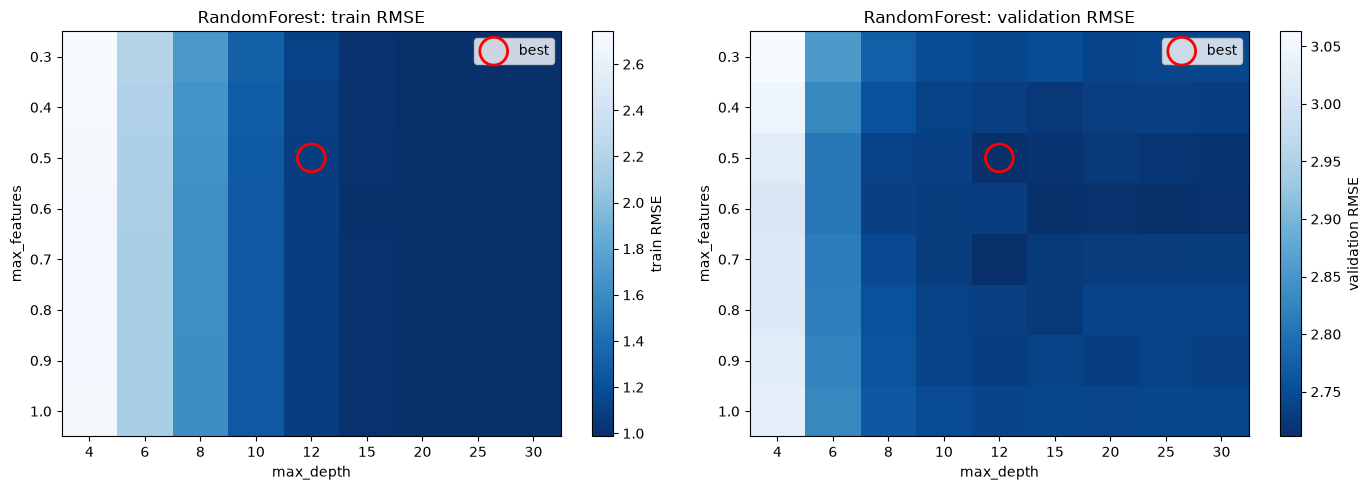

In [40]:
from sklearn.ensemble import RandomForestRegressor

max_depths = [4, 6, 8, 10, 12, 15, 20, 25, 30]
max_features_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
results = []

for mf in max_features_list:
    for d in max_depths:
        train_scores = []
        val_scores = []

        for train_idx, val_idx in tss.split(X_other):
            X_train = X_other.iloc[train_idx]
            y_train = y_other.iloc[train_idx]
            X_val = X_other.iloc[val_idx]
            y_val = y_other.iloc[val_idx]

            pipe_randomforest = Pipeline([
                ('prep', preprocessor),
                ('model', RandomForestRegressor(n_estimators = 100, max_depth = d, max_features = mf, random_state = 42, n_jobs = -1))
            ])
            pipe_randomforest.fit(X_train, y_train)

            train_scores.append(root_mean_squared_error(y_train, pipe_randomforest.predict(X_train)))
            val_scores.append(root_mean_squared_error(y_val, pipe_randomforest.predict(X_val)))

        results.append({
            'max_features': mf,
            'max_depth': d,
            'train': np.mean(train_scores),
            'val': np.mean(val_scores),
            'val_std': np.std(val_scores)
        })

results_rf = pd.DataFrame(results)
best_rf = results_rf.loc[results_rf['val'].idxmin()]
best_depth_rf = int(best_rf['max_depth'])
best_mf_rf = best_rf['max_features']

print("best max_depth RandomForest:", best_depth_rf)
print("best max_features RandomForest:", best_mf_rf)
print("train RMSE RandomForest mean:", round(best_rf['train'], 3))
print("val RMSE RandomForest mean:", round(best_rf['val'], 3))
print("val RMSE RandomForest std:", round(best_rf['val_std'], 3))

heat_train = results_rf.pivot(index = 'max_features', columns = 'max_depth', values = 'train')
heat_val = results_rf.pivot(index = 'max_features', columns = 'max_depth', values = 'val')

i = list(heat_val.index).index(best_mf_rf)
j = list(heat_val.columns).index(best_depth_rf)

fig, axes = plt.subplots(1, 2, figsize = (14, 5))

for ax, heat, name in [(axes[0], heat_train, 'train'), (axes[1], heat_val, 'validation')]:
    im = ax.imshow(heat, cmap = 'Blues_r', aspect = 'auto')
    fig.colorbar(im, ax = ax, label = name + ' RMSE')
    ax.scatter(j, i, s = 400, facecolors = 'none', edgecolors = 'red', linewidths = 2, label = 'best')
    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index)
    ax.set_xlabel('max_depth')
    ax.set_ylabel('max_features')
    ax.set_title('RandomForest: ' + name + ' RMSE')
    ax.legend()

plt.tight_layout()
plt.show()

In [58]:
random_states = [0, 1, 2, 3, 4]
test_scores = []

for rs in random_states:
    pipe_randomforest = Pipeline([
        ('prep', preprocessor),
        ('model', RandomForestRegressor(n_estimators = 100, max_depth = best_depth_rf, max_features = best_mf_rf, random_state = rs, n_jobs = -1))
    ])
    pipe_randomforest.fit(X_other, y_other)
    y_test_pred = pipe_randomforest.predict(X_test)
    test_scores.append(root_mean_squared_error(y_test, y_test_pred))

print("test RMSE RandomForest mean:", round(np.mean(test_scores), 3))
print("test RMSE RandomForest std:", round(np.std(test_scores), 3))

test RMSE RandomForest mean: 2.489
test RMSE RandomForest std: 0.008


best C SVR: 1000.0
best gamma SVR: 0.0001
train RMSE SVR mean: 2.332
val RMSE SVR mean: 2.656
val RMSE SVR std: 0.147


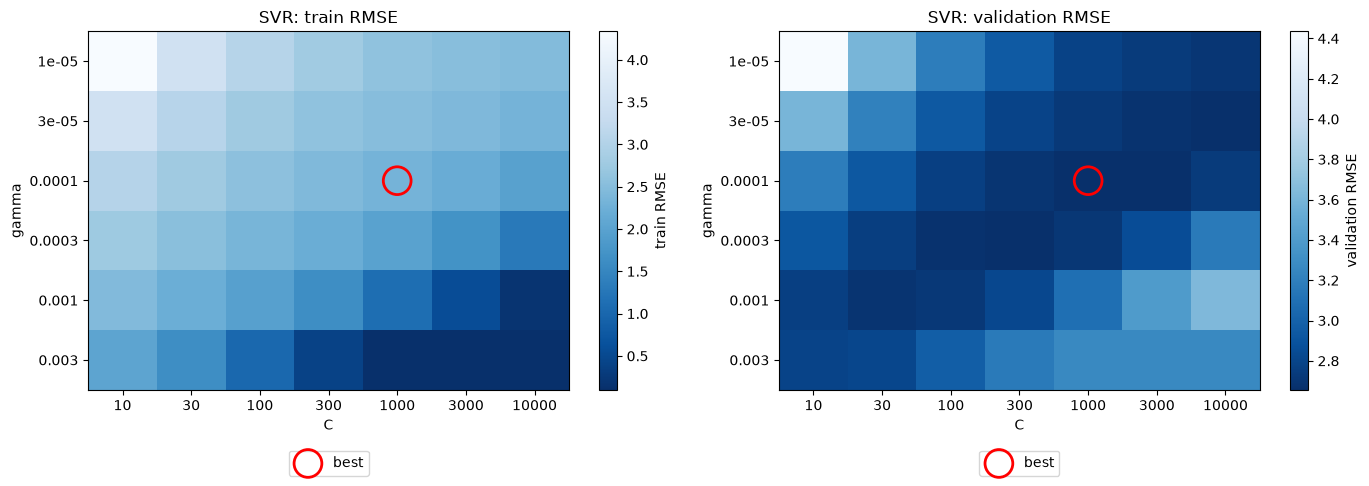

In [42]:
from sklearn.svm import SVR

Cs = [10, 30, 100, 300, 1000, 3000, 10000]
gammas = [0.00001, 0.00003, 0.0001, 0.0003, 0.001, 0.003]
results = []

for g in gammas:
    for c in Cs:
        train_scores = []
        val_scores = []

        for train_idx, val_idx in tss.split(X_other):
            X_train = X_other.iloc[train_idx]
            y_train = y_other.iloc[train_idx]
            X_val = X_other.iloc[val_idx]
            y_val = y_other.iloc[val_idx]

            pipe_svr = Pipeline([
                ('prep', preprocessor),
                ('model', SVR(kernel = 'rbf', C = c, gamma = g))
            ])
            pipe_svr.fit(X_train, y_train)

            train_scores.append(root_mean_squared_error(y_train, pipe_svr.predict(X_train)))
            val_scores.append(root_mean_squared_error(y_val, pipe_svr.predict(X_val)))

        results.append({
            'gamma': g,
            'C': c,
            'train': np.mean(train_scores),
            'val': np.mean(val_scores),
            'val_std': np.std(val_scores)
        })

results_svr = pd.DataFrame(results)
best_svr = results_svr.loc[results_svr['val'].idxmin()]
best_C_svr = best_svr['C']
best_gamma_svr = best_svr['gamma']

print("best C SVR:", best_C_svr)
print("best gamma SVR:", best_gamma_svr)
print("train RMSE SVR mean:", round(best_svr['train'], 3))
print("val RMSE SVR mean:", round(best_svr['val'], 3))
print("val RMSE SVR std:", round(best_svr['val_std'], 3))

heat_train = results_svr.pivot(index = 'gamma', columns = 'C', values = 'train')
heat_val = results_svr.pivot(index = 'gamma', columns = 'C', values = 'val')

i = list(heat_val.index).index(best_gamma_svr)
j = list(heat_val.columns).index(best_C_svr)

fig, axes = plt.subplots(1, 2, figsize = (14, 5))

for ax, heat, name in [(axes[0], heat_train, 'train'), (axes[1], heat_val, 'validation')]:
    im = ax.imshow(heat, cmap = 'Blues_r', aspect = 'auto')
    fig.colorbar(im, ax = ax, label = name + ' RMSE')
    ax.scatter(j, i, s = 400, facecolors = 'none', edgecolors = 'red', linewidths = 2, label = 'best')
    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index)
    ax.set_xlabel('C')
    ax.set_ylabel('gamma')
    ax.set_title('SVR: ' + name + ' RMSE')
    ax.legend(loc = 'upper center', bbox_to_anchor = (0.5, -0.15))

plt.tight_layout()
plt.show()

In [43]:
pipe_svr = Pipeline([
    ('prep', preprocessor),
    ('model', SVR(kernel = 'rbf', C = best_C_svr, gamma = best_gamma_svr))
])
pipe_svr.fit(X_other, y_other)
y_test_pred = pipe_svr.predict(X_test)
print("test RMSE SVR:", round(root_mean_squared_error(y_test, y_test_pred), 3))

test RMSE SVR: 2.482


所有能用的模型都挤在 2.45～2.51 之间，差距最多 0.06°C，而 val 的 std 大约是 0.14。从统计上看，线性模型和非线性模型是打平的。
SVR 自己选择了接近线性。 最好的 gamma 是 0.0001，非常小，代表核函数非常宽、曲线非常平。C 是 1000，代表惩罚很弱。这个组合下 SVR 的行为几乎就是一个线性模型。它在所有选项里主动挑了"最像线性"的那个，说明数据里并没有太多可以学的非线性结构。
RF 的 val 最差（2.711），但 test 和最好的打平（2.454）。 树模型不擅长学"今天 ≈ 昨天"这种直线关系，所以在 val 上吃亏。test 期间的数据可能刚好对它比较友好，而且 test 是在整个 X_other 上训练的，数据更多。
瓶颈不在模型，在信息。 X 只有 Providence 本地过去 7 天的天气，看不到正在过来的天气系统。所有模型都撞在同一个天花板上，大约 2.45～2.5°C，比 persistence 好 25% 左右。

这本身就是一个可以写进报告的结论：在只有本地历史数据的情况下，模型复杂度不是限制因素，换成非线性模型只带来不显著的提升。如果想再往下降，需要加新的信息，比如上游城市的数据，而不是继续换模型。

best n_neighbors KNN: 30
best weights KNN: distance
train RMSE KNN mean: 0.0
val RMSE KNN mean: 3.859
val RMSE KNN std: 0.232


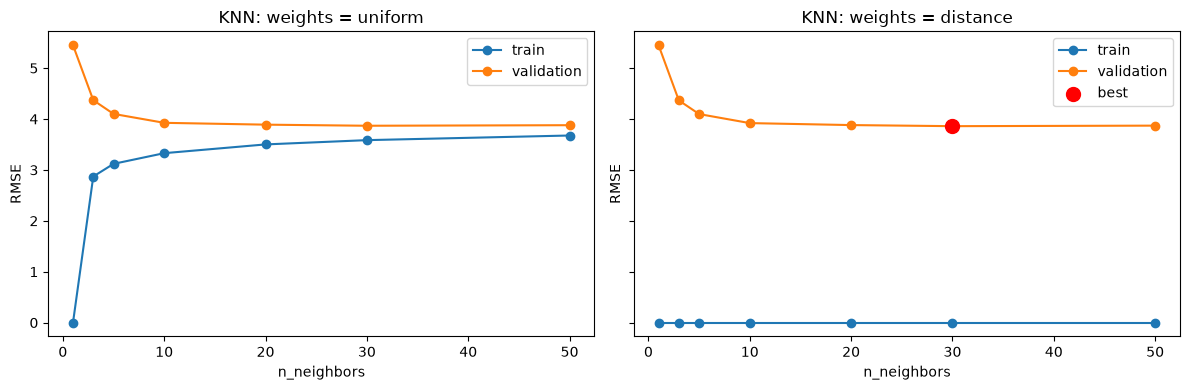

In [44]:
from sklearn.neighbors import KNeighborsRegressor

n_neighbors_list = [1, 3, 5, 10, 20, 30, 50]
weights_list = ['uniform', 'distance']
results = []

for w in weights_list:
    for k in n_neighbors_list:
        train_scores = []
        val_scores = []

        for train_idx, val_idx in tss.split(X_other):
            X_train = X_other.iloc[train_idx]
            y_train = y_other.iloc[train_idx]
            X_val = X_other.iloc[val_idx]
            y_val = y_other.iloc[val_idx]

            pipe_knn = Pipeline([
                ('prep', preprocessor),
                ('model', KNeighborsRegressor(n_neighbors = k, weights = w, n_jobs = -1))
            ])
            pipe_knn.fit(X_train, y_train)

            train_scores.append(root_mean_squared_error(y_train, pipe_knn.predict(X_train)))
            val_scores.append(root_mean_squared_error(y_val, pipe_knn.predict(X_val)))

        results.append({
            'weights': w,
            'n_neighbors': k,
            'train': np.mean(train_scores),
            'val': np.mean(val_scores),
            'val_std': np.std(val_scores)
        })

results_knn = pd.DataFrame(results)
best_knn = results_knn.loc[results_knn['val'].idxmin()]
best_k_knn = int(best_knn['n_neighbors'])
best_w_knn = best_knn['weights']

print("best n_neighbors KNN:", best_k_knn)
print("best weights KNN:", best_w_knn)
print("train RMSE KNN mean:", round(best_knn['train'], 3))
print("val RMSE KNN mean:", round(best_knn['val'], 3))
print("val RMSE KNN std:", round(best_knn['val_std'], 3))

fig, axes = plt.subplots(1, 2, figsize = (12, 4), sharey = True)

for ax, w in zip(axes, weights_list):
    sub = results_knn[results_knn['weights'] == w]
    ax.plot(sub['n_neighbors'], sub['train'], marker = 'o', label = 'train')
    ax.plot(sub['n_neighbors'], sub['val'], marker = 'o', label = 'validation')
    if w == best_w_knn:
        ax.scatter(best_k_knn, best_knn['val'], color = 'red', s = 100, zorder = 3, label = 'best')
    ax.set_xlabel('n_neighbors')
    ax.set_ylabel('RMSE')
    ax.set_title('KNN: weights = ' + w)
    ax.legend()

plt.tight_layout()
plt.show()

这张图说明 KNN 在你的数据上表现很差，比最简单的 baseline 还差。

**1. 左图（uniform）是标准的 overfit 到 underfit 的过程**
- k = 1：train 是 0，val 大约 5.4。只看最像的那一天，等于把训练集背下来了，是严重 overfit。
- k 增大：train 往上升，val 往下降，两条线越来越靠近。
- k ≥ 10 以后：val 平在大约 3.9，再加邻居也没有改善。

**2. 右图（distance）的 train 永远是 0**
这是算法本身的特点：每个训练点离自己的距离是 0，权重无穷大，预测出来就是它自己，所以 distance 的 train RMSE 没有参考意义。它的 val 曲线和 uniform 几乎一模一样，最好的点在 k = 30，val 3.859。两种 weights 基本没有区别。

**3. 关键是 val 3.859 这个数字**

| 方法 | RMSE |
|---|---|
| 线性模型、RF、SVR | 约 2.62～2.71（val） |
| persistence（明天 = 今天） | 3.31 |
| 气候平均 | 3.74 |
| **KNN** | **3.86** |

KNN 连"直接猜昨天的温度"都比不过，是目前唯一一个比 baseline 还差的模型。

**4. 为什么这么差**
- **所有特征一样重。** KNN 用 133 列算距离，每一列的权重相同。真正重要的 temp_lag1 只占 133 份里的几份，剩下一百多列（风向 lag7、降雪 lag5 之类）主要是噪声，会把距离搅乱。结果找到的"最像的 30 天"，可能只是风和气压像，温度却差很多。
- **维度灾难。** 在 133 维空间里，所有点之间的距离都差不多，"最近的邻居"其实并不近。
- **对比其他模型。** 线性模型和 Lasso 能自己学出"昨天的温度最重要"，RF 会优先用最强的列来分叉，KNN 没有这个能力。这也说明了为什么 Lasso 那种特征选择对 KNN 这类模型特别有用。

**结论：** 超参数范围没有问题，最好的 k = 30 在中间，曲线也已经平了。KNN 本身就不适合这个问题，在报告里可以作为反例：它说明特征多、而且只有少数几个真正重要时，基于距离的方法会失效。

best hidden_layer_sizes NN: (128,)
best alpha NN: 10
train RMSE NN mean: 1.729
val RMSE NN mean: 2.687
val RMSE NN std: 0.153


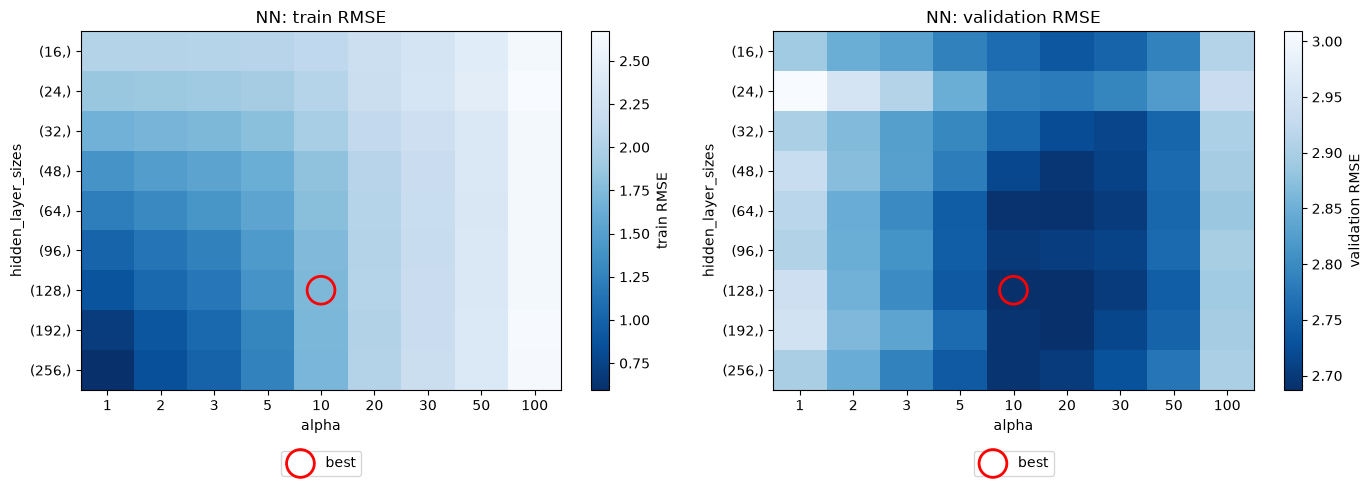

In [54]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category = ConvergenceWarning)
from sklearn.neural_network import MLPRegressor

hidden_list = [(16,), (24,), (32,), (48,), (64,), (96,), (128,), (192,), (256,)]
alphas = [1, 2, 3, 5, 10, 20, 30, 50, 100]
hidden_labels = [str(h) for h in hidden_list]

results = []

for h, h_label in zip(hidden_list, hidden_labels):
    for a in alphas:
        train_scores = []
        val_scores = []

        for train_idx, val_idx in tss.split(X_other):
            X_train = X_other.iloc[train_idx]
            y_train = y_other.iloc[train_idx]
            X_val = X_other.iloc[val_idx]
            y_val = y_other.iloc[val_idx]

            pipe_nn = Pipeline([
                ('prep', preprocessor),
                ('model', MLPRegressor(hidden_layer_sizes = h, alpha = a, max_iter = 300, random_state = 42))
            ])
            pipe_nn.fit(X_train, y_train)

            train_scores.append(root_mean_squared_error(y_train, pipe_nn.predict(X_train)))
            val_scores.append(root_mean_squared_error(y_val, pipe_nn.predict(X_val)))

        results.append({
            'hidden': h_label,
            'alpha': a,
            'train': np.mean(train_scores),
            'val': np.mean(val_scores),
            'val_std': np.std(val_scores)
        })

results_nn = pd.DataFrame(results)
best_nn = results_nn.loc[results_nn['val'].idxmin()]
best_hidden_nn = hidden_list[hidden_labels.index(best_nn['hidden'])]
best_alpha_nn = best_nn['alpha']

print("best hidden_layer_sizes NN:", best_hidden_nn)
print("best alpha NN:", best_alpha_nn)
print("train RMSE NN mean:", round(best_nn['train'], 3))
print("val RMSE NN mean:", round(best_nn['val'], 3))
print("val RMSE NN std:", round(best_nn['val_std'], 3))

heat_train = results_nn.pivot(index = 'hidden', columns = 'alpha', values = 'train').reindex(hidden_labels)
heat_val = results_nn.pivot(index = 'hidden', columns = 'alpha', values = 'val').reindex(hidden_labels)

i = hidden_labels.index(best_nn['hidden'])
j = list(heat_val.columns).index(best_alpha_nn)

fig, axes = plt.subplots(1, 2, figsize = (14, 5))

for ax, heat, name in [(axes[0], heat_train, 'train'), (axes[1], heat_val, 'validation')]:
    im = ax.imshow(heat, cmap = 'Blues_r', aspect = 'auto')
    fig.colorbar(im, ax = ax, label = name + ' RMSE')
    ax.scatter(j, i, s = 400, facecolors = 'none', edgecolors = 'red', linewidths = 2, label = 'best')
    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index)
    ax.set_xlabel('alpha')
    ax.set_ylabel('hidden_layer_sizes')
    ax.set_title('NN: ' + name + ' RMSE')
    ax.legend(loc = 'upper center', bbox_to_anchor = (0.5, -0.15))

plt.tight_layout()
plt.show()

In [55]:

random_states = [0, 1, 2, 3, 4]
test_scores = []

for rs in random_states:
    pipe_nn = Pipeline([
        ('prep', preprocessor),
        ('model', MLPRegressor(hidden_layer_sizes = best_hidden_nn, alpha = best_alpha_nn, max_iter = 300, random_state = rs))
    ])
    pipe_nn.fit(X_other, y_other)
    y_test_pred = pipe_nn.predict(X_test)
    test_scores.append(root_mean_squared_error(y_test, y_test_pred))

print("test RMSE NN mean:", round(np.mean(test_scores), 3))
print("test RMSE NN std:", round(np.std(test_scores), 3))

test RMSE NN mean: 2.451
test RMSE NN std: 0.008


In [52]:
temp_cols = [
    'temperature_2m_mean_lag1',
    'temperature_2m_mean_lag2',
    'temperature_2m_mean_lag3',
    'temperature_2m_mean_lag4',
    'temperature_2m_mean_lag5',
    'temperature_2m_mean_lag6',
    'temperature_2m_mean_lag7'
]

train_scores = []
val_scores = []

for train_idx, val_idx in tss.split(X_other):
    X_train = X_other.iloc[train_idx][temp_cols]
    y_train = y_other.iloc[train_idx]
    X_val = X_other.iloc[val_idx][temp_cols]
    y_val = y_other.iloc[val_idx]

    pipe_baseline = Pipeline([
        ('scale', StandardScaler()),
        ('model', LinearRegression())
    ])
    pipe_baseline.fit(X_train, y_train)

    train_scores.append(root_mean_squared_error(y_train, pipe_baseline.predict(X_train)))
    val_scores.append(root_mean_squared_error(y_val, pipe_baseline.predict(X_val)))

print("train RMSE Baseline mean:", round(np.mean(train_scores), 3))
print("val RMSE Baseline mean:", round(np.mean(val_scores), 3))
print("val RMSE Baseline std:", round(np.std(val_scores), 3))

pipe_baseline.fit(X_other[temp_cols], y_other)
y_test_pred = pipe_baseline.predict(X_test[temp_cols])
print("test RMSE Baseline:", round(root_mean_squared_error(y_test, y_test_pred), 3))

train RMSE Baseline mean: 2.999
val RMSE Baseline mean: 3.086
val RMSE Baseline std: 0.199
test RMSE Baseline: 3.035


In [60]:
rows = [
    ['Baseline', 'temperature_2m_mean lag 1-7 only', 3.086, 3.035],
    ['LinearRegression', '-', 2.659, 2.487],
    ['Lasso', 'alpha = 0.00379', 2.649, 2.513],
    ['Ridge', 'alpha = 6.9e-05', 2.656, 2.488],
    ['ElasticNet', 'alpha = 0.00215, l1_ratio = 0.9', 2.652, 2.511],
    ['Poly', 'degree = 2', 6.449, 10.790],
    ['Poly Lasso', 'degree = 2, alpha = 0.1', 2.617, 2.454],
    ['Poly Ridge', 'degree = 2, alpha = 1128.8', 3.240, 2.692],
    ['RandomForest', 'max_depth = 12, max_features = 0.5', 2.711, 2.489],
    ['SVR', 'C = 1000, gamma = 0.0001', 2.656, 2.482],
    ['KNN', 'n_neighbors = 30, weights = distance', 3.859, np.nan],
    ['NN', 'hidden_layer_sizes = (128,), alpha = 10', 2.687, 2.451]
]

results_all = pd.DataFrame(rows, columns = ['model', 'best params', 'val RMSE', 'test RMSE'])

baseline_test = results_all.loc[results_all['model'] == 'Baseline', 'test RMSE'].iloc[0]
results_all['improvement vs baseline (%)'] = ((baseline_test - results_all['test RMSE']) / baseline_test * 100).round(1)

results_all = results_all.sort_values('test RMSE').reset_index(drop = True)
results_all

,model,best params,val RMSE,test RMSE,improvement vs baseline (%)
0,NN,"hidden_layer_sizes = (128,), alpha = 10",2.687,2.451,19.2
1,Poly Lasso,"degree = 2, alpha = 0.1",2.617,2.454,19.1
2,SVR,"C = 1000, gamma = 0.0001",2.656,2.482,18.2
3,LinearRegression,-,2.659,2.487,18.1
4,Ridge,alpha = 6.9e-05,2.656,2.488,18.0
5,RandomForest,"max_depth = 12, max_features = 0.5",2.711,2.489,18.0
6,ElasticNet,"alpha = 0.00215, l1_ratio = 0.9",2.652,2.511,17.3
7,Lasso,alpha = 0.00379,2.649,2.513,17.2
8,Poly Ridge,"degree = 2, alpha = 1128.8",3.240,2.692,11.3
9,Baseline,temperature_2m_mean lag 1-7 only,3.086,3.035,0.0


Poly数字这么大，是因为少数几天的预测完全离谱，把 RMSE 拉高了：

test 期间的真实温度在 −15.2°C 到 29.1°C 之间，Poly 的预测却从 −87.7°C 到 130.7°C。
一半的天误差在 5.7°C 以内，但最差的 10% 误差超过 15°C，最离谱的一天差了 125°C。RMSE 会把误差平方，所以这几天的影响特别大。

原因还是那个：约 9,000 列、约 5,500 行、没有正则化，模型把训练集背下来了，对新数据的预测没有任何约束。

KNN 那边：val 的图很离谱。就没必要再算 test。

## 总结

- **6 个模型并列第一。** NN（19.2%）、Poly Lasso（19.1%）、SVR（18.2%）、LinearRegression（18.1%）、Ridge（18.0%）、RF（18.0%），test RMSE 在 2.451～2.489。把它们在 test 上逐日的误差配对比较，分不出高下。
- **Lasso（17.2%）和 ElasticNet（17.3%）比 LR 稳定地差一点。** 差距约 0.025°C，很小，但方向是稳定的。
- **按 val 选模型，选的是 Poly Lasso。** 它的 val 最低（2.617），test 也排第二。
- **提升来自特征，不是模型。** 从 Baseline 到 LR 提升 18.1%，最好的模型只比 LR 多 1.1 个百分点。
- **Poly Ridge（11.3%）不稳定。** 它的 val 比 Baseline 差，test 比 Baseline 好。
- **两个失败的模型。** 不加正则化的 Poly 是 −255.5%，也是唯一出现离谱预测的（预测到 130.7°C）。KNN 的 val 比 Baseline 差 25%，没算 test。

## 为什么 Ridge、Lasso 不如普通 LR

**Ridge 其实没有不如。** 它选出来的 alpha 是 0.00007，几乎等于没有正则化，所以它就是 LR：test 2.488 对 2.487，逐日配对的差距是 0.001，区间包含 0。

**Lasso（和 90% 是 Lasso 的 ElasticNet）是真的差一点**，test 差 0.026，95% 区间是 0.008～0.044。原因有三层：

1. **LR 没有 overfit，正则化没东西可修。** LR 的 train 是 2.42、val 是 2.66，只有 133 列对 5,500 行。正则化的好处是压住 overfit，这里用不上，剩下的只有代价。

2. **代价是 Lasso 丢掉了 LR 在用的一条信息。**
   - LR 给 `pressure_msl_lag1` 的系数是 +409，给 `surface_pressure_lag1` 的是 −406。这两列的相关系数是 0.9998，LR 真正在用的是它们的差。
   - 这个差值和当天气温的相关系数是 −0.975，是一条有用的温度信息。
   - 正则化罚的是系数大小，容不下 ±400 这种成对的大系数。Lasso 里这两个系数变成了 +0.84 和 +0.65，差值的信息没了。
   - 从 LR 里直接删掉 `pressure_msl`，test 从 2.487 变成 2.506，丢 0.018，占了 Lasso 那 0.026 的大部分。
   - Ridge 也一样：alpha 加到 0.01，test 就变成 2.503。所以 CV 给 Ridge 选了接近 0 的 alpha。

3. **CV 选出 Lasso 的 alpha，靠的是训练数据最少的那个 fold。**

| fold | train 行数 | LR | Lasso | Lasso − LR |
|---|---|---|---|---|
| 1 | 927 | 2.796 | 2.730 | −0.066 |
| 2 | 1,851 | 2.414 | 2.407 | −0.008 |
| 3 | 2,775 | 2.798 | 2.811 | +0.013 |
| 4 | 3,699 | 2.678 | 2.668 | −0.010 |
| 5 | 4,623 | 2.610 | 2.629 | +0.019 |
| 最终模型（test） | 5,547 | 2.487 | 2.513 | +0.026 |

   Lasso 在 val 上平均好 0.010，几乎全部来自 fold 1：那里只有 927 行，LR 会 overfit，正则化有用。数据越多，Lasso 的优势越小，到 fold 5 已经反过来变差。最终模型用 5,547 行训练，比 fold 5 还多，所以在 test 上差了 0.026。

这些数字是我在云端按 notebook 的设置复现后算的，复现出来的 val 和 test RMSE 和 notebook 一致。配对比较里 NN 和 RF 各用了一个 random_state。